In [ ]:
#Female cardio
## 1. Učitavanje i formiranje dataseta

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import kagglehub

from kagglehub import KaggleDatasetAdapter

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "valakhorasani/gym-members-exercise-dataset",
    "gym_members_exercise_tracking.csv"
)

df_fc = df[
    (df['Gender'] == 'Female') &
    (df['Workout_Type'] == 'Cardio')
].copy()

print("Dimenzije Female Cardio dataseta:", df_fc.shape)

/Users/brankomitic/DataspellProjects/alternativni_dataset_diplomski/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/28/tt6vttm91r1c29lt4s1fr9z40000gn/T/ipykernel_2976/2466119202.py:9: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Dimenzije Female Cardio dataseta: (126, 15)


In [ ]:
## 2. Priprema podataka

### 2.1. Provera NA vrednosti

In [2]:
print(df_fc.isnull().sum())

Age                              0
Gender                           0
Weight (kg)                      0
Height (m)                       0
Max_BPM                          0
Avg_BPM                          0
Resting_BPM                      0
Session_Duration (hours)         0
Calories_Burned                  0
Workout_Type                     0
Fat_Percentage                   0
Water_Intake (liters)            0
Workout_Frequency (days/week)    0
Experience_Level                 0
BMI                              0
dtype: int64


In [ ]:
#opet bez nan vrednosti

In [ ]:
### 2.2. Korelaciona analiza

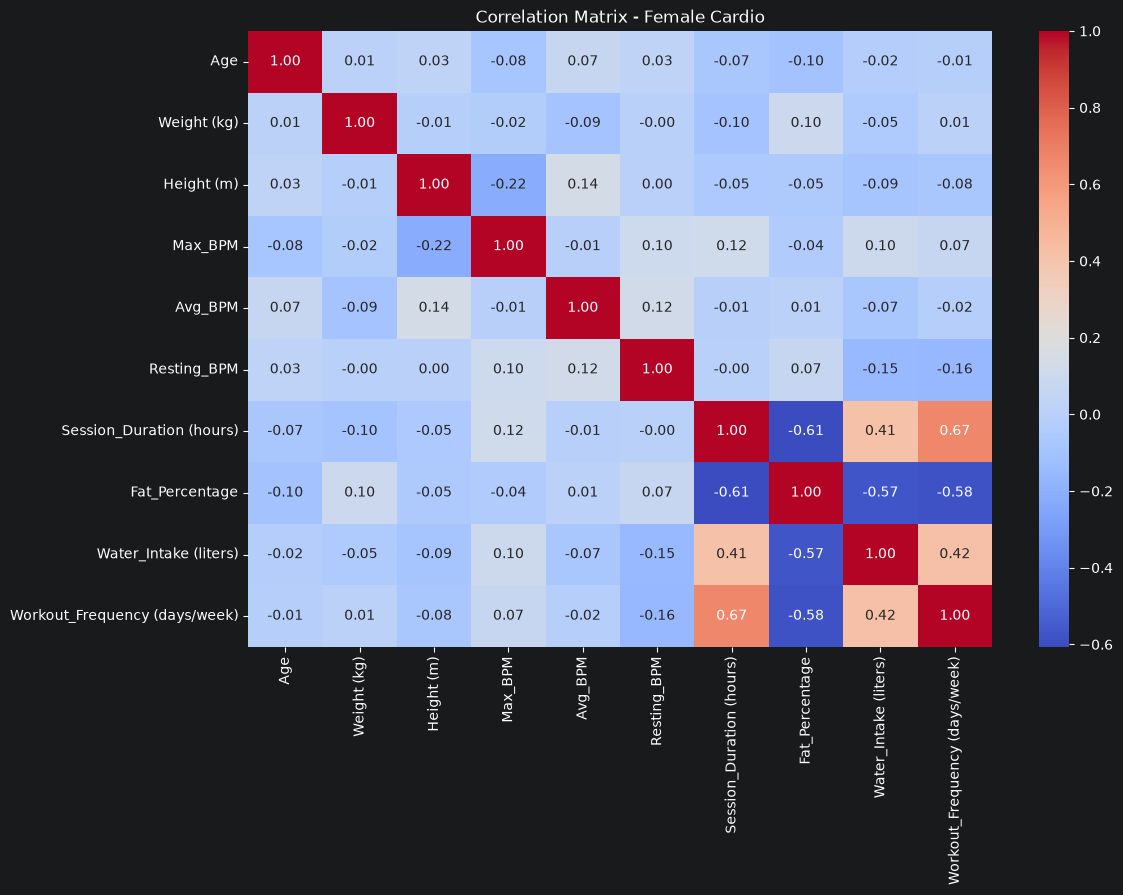

In [3]:
features = [
    'Age',
    'Weight (kg)',
    'Height (m)',
    'Max_BPM',
    'Avg_BPM',
    'Resting_BPM',
    'Session_Duration (hours)',
    'Fat_Percentage',
    'Water_Intake (liters)',
    'Workout_Frequency (days/week)'
]

corr_matrix = df_fc[features].corr()

plt.figure(figsize=(12, 8))
sb.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix - Female Cardio')
plt.show()

In [ ]:
#analogno ko pre sve ispod 0.7

In [ ]:
### 2.3. Analiza outliera

In [4]:
Q1 = df_fc[features].quantile(0.25)
Q3 = df_fc[features].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_df = pd.DataFrame({
    'Donji outlieri': (df_fc[features] < lower_bound).sum(),
    'Gornji outlieri': (df_fc[features] > upper_bound).sum()
})

outliers_df['Ukupno'] = outliers_df.sum(axis=1)

print(outliers_df)

                               Donji outlieri  Gornji outlieri  Ukupno
Age                                         0                0       0
Weight (kg)                                 0                0       0
Height (m)                                  0                0       0
Max_BPM                                     0                0       0
Avg_BPM                                     0                0       0
Resting_BPM                                 0                0       0
Session_Duration (hours)                    0                0       0
Fat_Percentage                              4                0       4
Water_Intake (liters)                       0                0       0
Workout_Frequency (days/week)               0                0       0


In [5]:
from scipy.stats.mstats import winsorize

column = 'Fat_Percentage'

print("Vrednosti outliera:")
print(df_fc.loc[df_fc[column] < lower_bound[column], column].values)

for limit in np.arange(0.01, 0.11, 0.01):
    temp = pd.Series(
        np.asarray(
            winsorize(
                df_fc[column].to_numpy().copy(),
                limits=[limit, 0]
            )
        )
    )

    Q1_temp = temp.quantile(0.25)
    Q3_temp = temp.quantile(0.75)
    IQR_temp = Q3_temp - Q1_temp

    lower_temp = Q1_temp - 1.5 * IQR_temp

    n_outliers = (temp < lower_temp).sum()

    print(f"Limit {limit:.2f}: {n_outliers} outliera")

Vrednosti outliera:
[15.5 15.9 16.2 16.1]
Limit 0.01: 4 outliera
Limit 0.02: 4 outliera
Limit 0.03: 4 outliera
Limit 0.04: 0 outliera
Limit 0.05: 0 outliera
Limit 0.06: 0 outliera
Limit 0.07: 0 outliera
Limit 0.08: 0 outliera
Limit 0.09: 0 outliera
Limit 0.10: 0 outliera


In [ ]:
#Za 0.04 limit za donje outliere nemamo vise outliera za fat percentage pa cemo to da uradimo za wins

In [6]:
df_fc['Fat_Percentage'] = np.asarray(
    winsorize(
        df_fc['Fat_Percentage'].to_numpy().copy(),
        limits=[0.04, 0]
    )
)

In [7]:
Q1 = df_fc[features].quantile(0.25)
Q3 = df_fc[features].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_df = pd.DataFrame({
    'Donji outlieri': (df_fc[features] < lower_bound).sum(),
    'Gornji outlieri': (df_fc[features] > upper_bound).sum()
})

outliers_df['Ukupno'] = outliers_df.sum(axis=1)

print(outliers_df)

                               Donji outlieri  Gornji outlieri  Ukupno
Age                                         0                0       0
Weight (kg)                                 0                0       0
Height (m)                                  0                0       0
Max_BPM                                     0                0       0
Avg_BPM                                     0                0       0
Resting_BPM                                 0                0       0
Session_Duration (hours)                    0                0       0
Fat_Percentage                              0                0       0
Water_Intake (liters)                       0                0       0
Workout_Frequency (days/week)               0                0       0


In [ ]:
#Nema vise outliera

In [ ]:
#2.4 MinMax skaliranje

In [8]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_fc = scaler.fit_transform(df_fc[features])

X_fc = pd.DataFrame(
    X_fc,
    columns=features,
    index=df_fc.index
)

print("Minimalne vrednosti:")
print(X_fc.min())

print("\nMaksimalne vrednosti:")
print(X_fc.max())

Minimalne vrednosti:
Age                              0.0
Weight (kg)                      0.0
Height (m)                       0.0
Max_BPM                          0.0
Avg_BPM                          0.0
Resting_BPM                      0.0
Session_Duration (hours)         0.0
Fat_Percentage                   0.0
Water_Intake (liters)            0.0
Workout_Frequency (days/week)    0.0
dtype: float64

Maksimalne vrednosti:
Age                              1.0
Weight (kg)                      1.0
Height (m)                       1.0
Max_BPM                          1.0
Avg_BPM                          1.0
Resting_BPM                      1.0
Session_Duration (hours)         1.0
Fat_Percentage                   1.0
Water_Intake (liters)            1.0
Workout_Frequency (days/week)    1.0
dtype: float64


In [ ]:
## 3. Određivanje optimalnog K

### 3.1. Elbow metoda

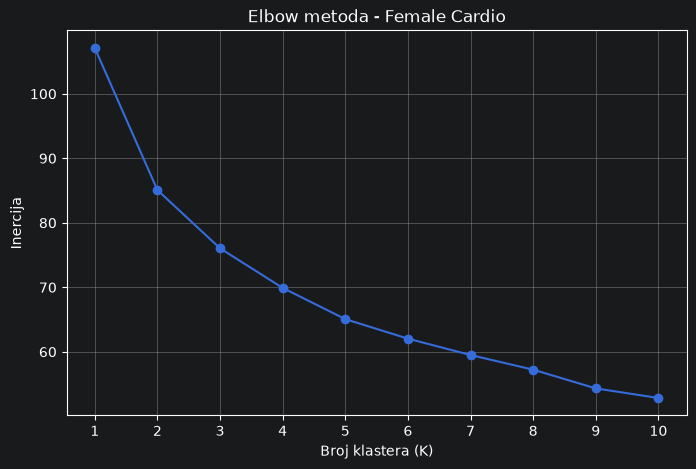

Rezultati Elbow metode:
K=1: Inercija=107.10
K=2: Inercija=85.07
K=3: Inercija=76.04
K=4: Inercija=69.90
K=5: Inercija=65.06
K=6: Inercija=62.03
K=7: Inercija=59.50
K=8: Inercija=57.22
K=9: Inercija=54.32
K=10: Inercija=52.83


In [9]:
from sklearn.cluster import KMeans

inertias = []
K = range(1, 11)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_fc)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K, inertias, marker='o')
plt.xlabel('Broj klastera (K)')
plt.ylabel('Inercija')
plt.title('Elbow metoda - Female Cardio')
plt.xticks(K)
plt.grid(True)
plt.show()

print("Rezultati Elbow metode:")
for k, inertia in zip(K, inertias):
    print(f"K={k}: Inercija={inertia:.2f}")

In [ ]:
### 3.2. Silhouette metoda

K=2: Silhouette=0.2321
K=3: Silhouette=0.1467
K=4: Silhouette=0.1356
K=5: Silhouette=0.1395
K=6: Silhouette=0.1323
K=7: Silhouette=0.1210
K=8: Silhouette=0.1141
K=9: Silhouette=0.1160
K=10: Silhouette=0.1337


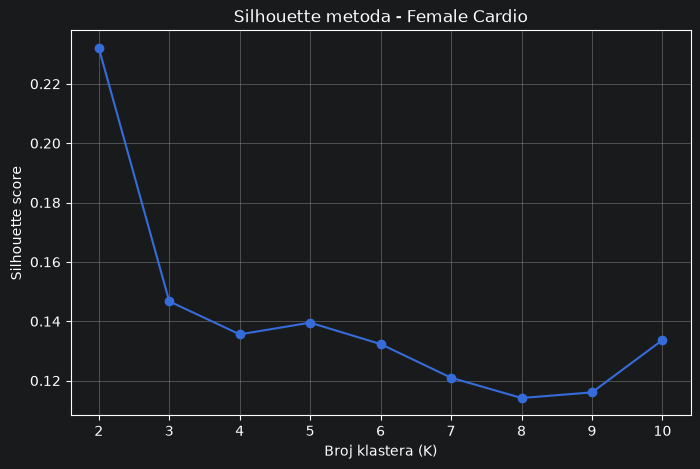

In [10]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_fc)
    score = silhouette_score(X_fc, labels)

    silhouette_scores.append(score)
    print(f"K={k}: Silhouette={score:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel('Broj klastera (K)')
plt.ylabel('Silhouette score')
plt.title('Silhouette metoda - Female Cardio')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [ ]:
#Najbolje K=2 opet

In [ ]:
### 3.3. Dendrogrami

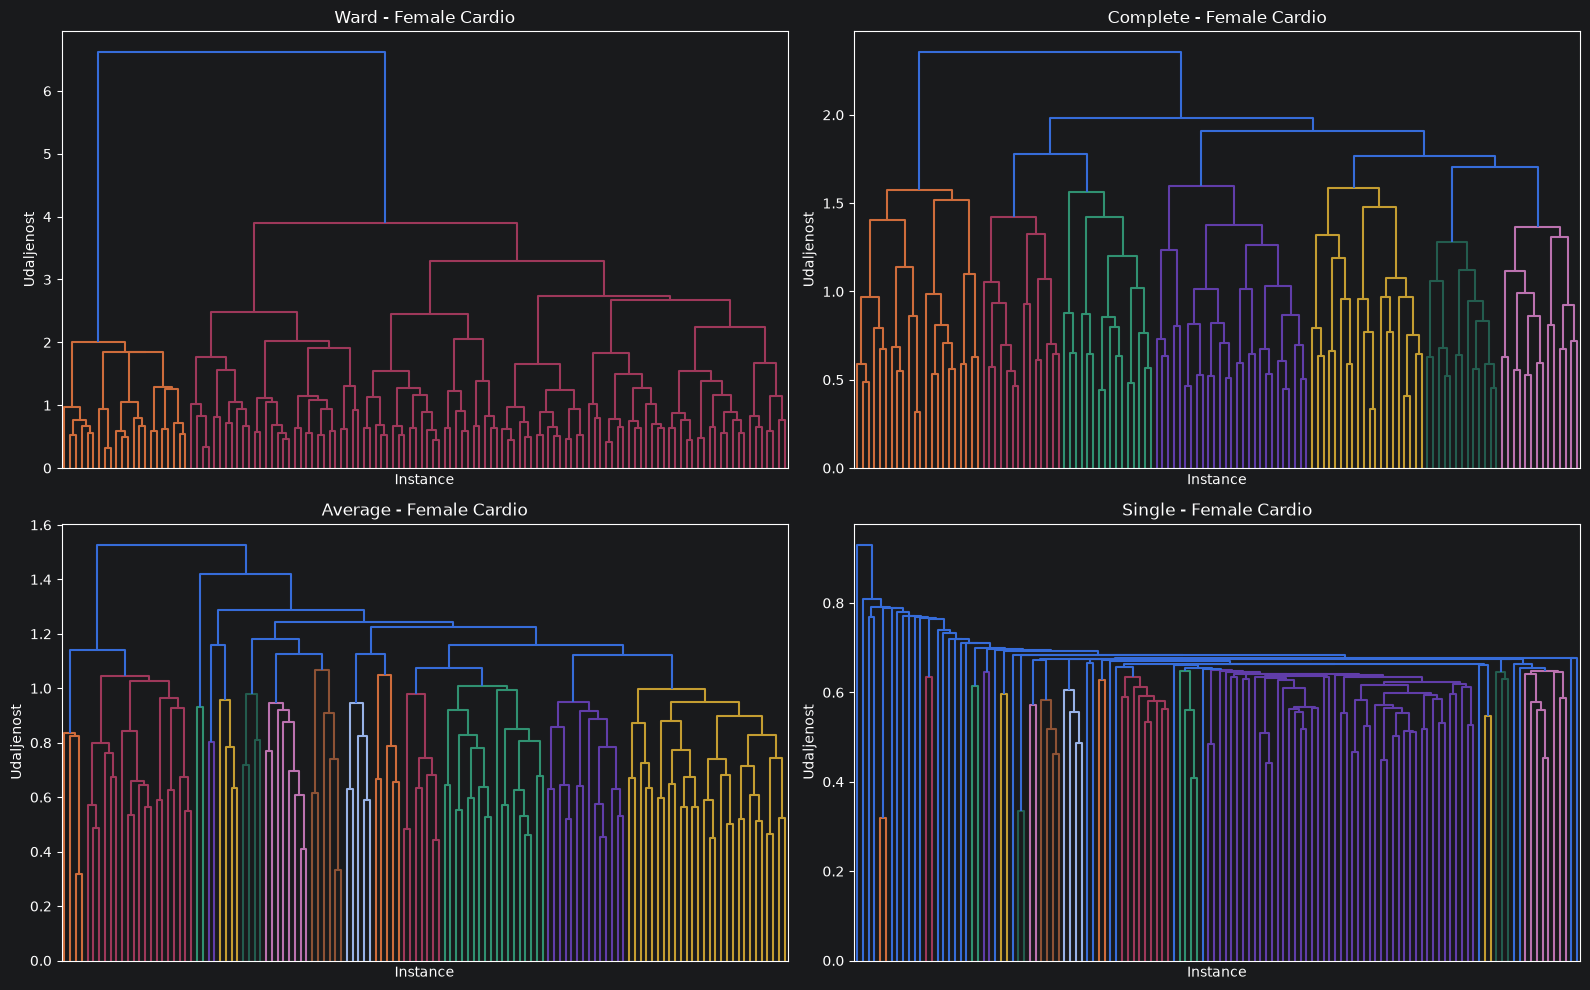

In [11]:
from scipy.cluster.hierarchy import linkage, dendrogram

methods = ['ward', 'complete', 'average', 'single']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, method in zip(axes.flatten(), methods):
    Z = linkage(X_fc, method=method)

    dendrogram(
        Z,
        ax=ax,
        no_labels=True
    )

    ax.set_title(f'{method.capitalize()} - Female Cardio')
    ax.set_xlabel('Instance')
    ax.set_ylabel('Udaljenost')

plt.tight_layout()
plt.show()

In [ ]:
## 4. Klasterizacija i tumačenje klastera

### 4.1. KMeans klasterizacija i tumačenje klastera

In [12]:
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

df_fc['Cluster_KMeans'] = kmeans.fit_predict(X_fc)

print("Broj instanci po klasterima:")
print(df_fc['Cluster_KMeans'].value_counts().sort_index())

print("\nSilhouette score:")
print(silhouette_score(X_fc, df_fc['Cluster_KMeans']))

Broj instanci po klasterima:
Cluster_KMeans
0     26
1    100
Name: count, dtype: int64

Silhouette score:
0.23207157255958466


In [13]:
### 4.1.1. Tumačenje KMeans klastera

In [14]:
cluster_summary = df_fc.groupby('Cluster_KMeans')[
    features + ['Calories_Burned']
].mean().round(2)

print("Prosečne vrednosti atributa po klasterima:")
print(cluster_summary.to_string())

Prosečne vrednosti atributa po klasterima:
                  Age  Weight (kg)  Height (m)  Max_BPM  Avg_BPM  Resting_BPM  Session_Duration (hours)  Fat_Percentage  Water_Intake (liters)  Workout_Frequency (days/week)  Calories_Burned
Cluster_KMeans                                                                                                                                                                                
0               37.23        61.62        1.64   183.27   142.12        61.88                      1.69           19.22                   2.68                           4.50          1140.96
1               36.96        61.94        1.65   180.20   144.66        61.81                      1.08           30.24                   2.09                           2.91           755.19


In [ ]:
#Klaster 0 je sad onaj manji klaster sa 26 instanci sa duzim treninzima cescim i nizim procentom masti,a takodje ima i 385 kalorija vecu prosecnu potrosnju
#Silhoiuete od 0.2321 ukazuje takodje na slabu razvijenost klastera

In [ ]:
### 4.2. Hijerarhijska klasterizacija i tumačenje klastera

In [15]:
from sklearn.cluster import AgglomerativeClustering

methods = ['ward', 'complete', 'average', 'single']

for method in methods:
    model = AgglomerativeClustering(
        n_clusters=2,
        linkage=method
    )

    labels = model.fit_predict(X_fc)

    print(f"\n===== {method.upper()} =====")
    print("Broj instanci po klasterima:")
    print(pd.Series(labels).value_counts().sort_index())
    print(f"Silhouette score: {silhouette_score(X_fc, labels):.4f}")


===== WARD =====
Broj instanci po klasterima:
0    104
1     22
Name: count, dtype: int64
Silhouette score: 0.2466

===== COMPLETE =====
Broj instanci po klasterima:
0    104
1     22
Name: count, dtype: int64
Silhouette score: 0.2466

===== AVERAGE =====
Broj instanci po klasterima:
0    103
1     23
Name: count, dtype: int64
Silhouette score: 0.2439

===== SINGLE =====
Broj instanci po klasterima:
0    125
1      1
Name: count, dtype: int64
Silhouette score: 0.1268


In [ ]:
#Ward i complete opet daju nesto bolje rezultate od Kmeans pa cemo ward da koristimo opet

In [ ]:
### 4.2.1. Tumačenje hijerarhijskih klastera (Ward)

In [16]:
ward = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

df_fc['Cluster_Ward'] = ward.fit_predict(X_fc)

ward_summary = df_fc.groupby('Cluster_Ward')[
    features + ['Calories_Burned']
].mean().round(2)

print("Prosečne vrednosti po Ward klasterima:")
print(ward_summary.to_string())

print("\nPoređenje KMeans i Ward klastera:")
print(pd.crosstab(
    df_fc['Cluster_KMeans'],
    df_fc['Cluster_Ward']
))

Prosečne vrednosti po Ward klasterima:
                Age  Weight (kg)  Height (m)  Max_BPM  Avg_BPM  Resting_BPM  Session_Duration (hours)  Fat_Percentage  Water_Intake (liters)  Workout_Frequency (days/week)  Calories_Burned
Cluster_Ward                                                                                                                                                                                
0             36.62        62.23        1.65   180.43   144.65        61.91                      1.09           30.09                   2.11                           2.95           763.16
1             38.86        60.20        1.64   182.73   141.68        61.41                      1.75           17.95                   2.70                           4.59          1173.41

Poređenje KMeans i Ward klastera:
Cluster_Ward      0   1
Cluster_KMeans         
0                 4  22
1               100   0


In [ ]:
#U ovom slucaju imamo manje instanci u manjem klaster a vise u vecem al zbog Silhoeute score moze se reci da su razvijeniji klasteri,interpretacija ista